# 11 — NMF vs. Embedding Topics

> **Does an embedding-based topic model surface different complaint themes than the transparent NMF baseline?**

| | |
|---|---|
| **Audience** | Data scientists, MLOps reviewers |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-28 |
| **Runtime** | ~90 s on the bundled sample (first run downloads ~80 MB of model weights). |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

The project's TF-IDF + NMF baseline is interpretable and fast. Modern NLP can do better &mdash; sometimes. This notebook fits both methods on the same complaints, compares the topic assignments, and surfaces the trade-offs so a reader can decide which method to ship.

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Section **1** fits the **NMF baseline** &mdash; the contract-required model.
3. Section **2** fits the **embedding baseline** (Sentence-Transformers + KMeans + c-TF-IDF labels).
4. Section **3** compares the two: topic counts, topic-term overlap, assignment agreement, and per-method risk concentration.
5. The **Insights** section calls out what each method captures that the other misses.
6. The **Limitations** section flags the cost-of-ownership trade-off.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/11/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.nlp.embedding_topics import fit_embedding_topics
from cx_complaints.nlp.topics import fit_nmf_topics
from cx_complaints.reports.notebook_utils import (
    PALETTE,
    horizontal_bar,
    load_complaints,
    save_figure,
    save_table,
    setup_notebook,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("11")
N_TOPICS = 8


## 1. Fit the NMF baseline

The NMF backend uses TF-IDF (`min_df=5`, n-grams 1-2) plus NMF with a fixed seed. It is the project's contract baseline &mdash; transparent, fast, and unchanged.


In [2]:
complaints = load_complaints(ctx)
text_mask = complaints["clean_text"].fillna("").astype(str).str.strip() != ""
print(f"Total complaints: {len(complaints):,}  |  With narrative: {int(text_mask.sum()):,}")
complaints[["complaint_id", "product", "risk_level"]].head()


Total complaints: 1,000  |  With narrative: 1,000


,complaint_id,product,risk_level
0,9316329,Credit reporting or other personal consumer re...,high
1,9282035,Credit reporting or other personal consumer re...,medium
2,9265219,Credit reporting or other personal consumer re...,medium
3,9333110,Credit reporting or other personal consumer re...,medium
4,9357247,Credit reporting or other personal consumer re...,medium


In [3]:
nmf_result = fit_nmf_topics(
    complaints.loc[text_mask, "clean_text"],
    n_topics=N_TOPICS,
)
nmf_terms = nmf_result.topic_terms
nmf_assignments = pd.Series(-1, index=complaints.index, dtype=int)
nmf_assignments.loc[text_mask] = nmf_result.assignments["topic_id"].to_numpy().astype(int)
print(f"NMF fitted {nmf_terms['topic_id'].nunique()} topics over {int(text_mask.sum()):,} narratives.")


NMF fitted 8 topics over 1,000 narratives.


## 2. Fit the embedding baseline

The embedding backend encodes each narrative with `sentence-transformers/all-MiniLM-L6-v2` (~80 MB, CPU-friendly), then runs KMeans over the embeddings and labels each cluster with class-based TF-IDF terms &mdash; the same labelling trick BERTopic popularised. The first run downloads the model; subsequent runs use the local cache.


In [4]:
embedding_result = fit_embedding_topics(
    complaints.loc[text_mask, "clean_text"],
    n_topics=N_TOPICS,
)
emb_terms = embedding_result.topic_terms
emb_assignments = pd.Series(-1, index=complaints.index, dtype=int)
emb_assignments.loc[text_mask] = embedding_result.assignments.loc[text_mask, "topic_id"].to_numpy().astype(int)
print(f"Embedding model: {embedding_result.encoder_name}")
print(f"Cluster sizes: {pd.Series(emb_assignments[text_mask]).value_counts().sort_index().to_dict()}")


C:\Users\diogo\AppData\Local\pypoetry\Cache\virtualenvs\cx-complaint-intelligence-s3yvBmH--py3.12\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Embedding model: sentence-transformers/all-MiniLM-L6-v2
Cluster sizes: {0: 202, 1: 137, 2: 181, 3: 88, 4: 171, 5: 82, 6: 50, 7: 89}


## 3. Side-by-side comparison

The two methods may discover different numbers of populated topics and different vocabularies. The cells below build:

- a topic-label table with the top six terms per topic per method;
- a contingency table that maps NMF topics to embedding clusters and vice versa;
- a per-topic risk profile so we can see whether each method concentrates risk differently.


In [5]:
def _topic_label_table(topic_terms: pd.DataFrame, top_n: int = 6) -> pd.DataFrame:
    return (
        topic_terms.sort_values(["topic_id", "rank"])
        .groupby("topic_id")["term"]
        .apply(lambda terms: ", ".join(terms.head(top_n).astype(str)))
        .rename("topic_label")
        .reset_index()
    )

labels = (
    _topic_label_table(nmf_terms).assign(method="nmf")
    .merge(_topic_label_table(emb_terms).assign(method="embedding"), how="outer", on=["topic_id", "method", "topic_label"])
)
labels_side_by_side = (
    pd.DataFrame({
        "topic_id": list(range(N_TOPICS)),
        "nmf_label": _topic_label_table(nmf_terms).set_index("topic_id")["topic_label"].reindex(range(N_TOPICS)).fillna("(unused)").values,
        "embedding_label": _topic_label_table(emb_terms).set_index("topic_id")["topic_label"].reindex(range(N_TOPICS)).fillna("(unused)").values,
    })
)
labels_side_by_side


,topic_id,nmf_label,embedding_label
0,0,"redacted, redacted redacted, money, account, b...","redacted, redacted redacted, account, money, b..."
1,1,"consumer, 15, section, states, 1681, consumer ...","report, credit, accounts, credit report, infor..."
2,2,"accounts, fcra 605b, significance eliminating,...","redacted, redacted redacted, credit, redacted ..."
3,3,"payment, late, payments, creditor, late paymen...","redacted, redacted redacted, consumer, 15, sec..."
4,4,"credit, report, credit report, information, ac...","redacted, redacted redacted, credit, report, i..."
5,5,"payments, perplexing discover, perplexing, upd...","late, payment, redacted, payments, redacted re..."
6,6,"letters, party involved, really sure, falsely ...","redacted, redacted redacted, date inquiry, inq..."
7,7,"consumer reports, consent, consumer, reports, ...","credit, report, accounts, credit report, fcra ..."


In [6]:
crosstab = pd.crosstab(
    nmf_assignments[text_mask].rename("nmf_topic"),
    emb_assignments[text_mask].rename("embedding_topic"),
)
crosstab


embedding_topic,0,1,2,3,4,5,6,7
nmf_topic,,,,,,,,
0,125,3,144,16,31,1,6,3
1,4,0,2,52,5,0,0,0
2,0,0,0,0,0,0,0,39
3,14,1,0,0,1,49,1,0
4,57,132,31,7,92,3,41,47
5,0,0,0,0,0,20,0,0
6,0,0,0,0,21,0,0,0
7,2,1,4,13,21,9,2,0


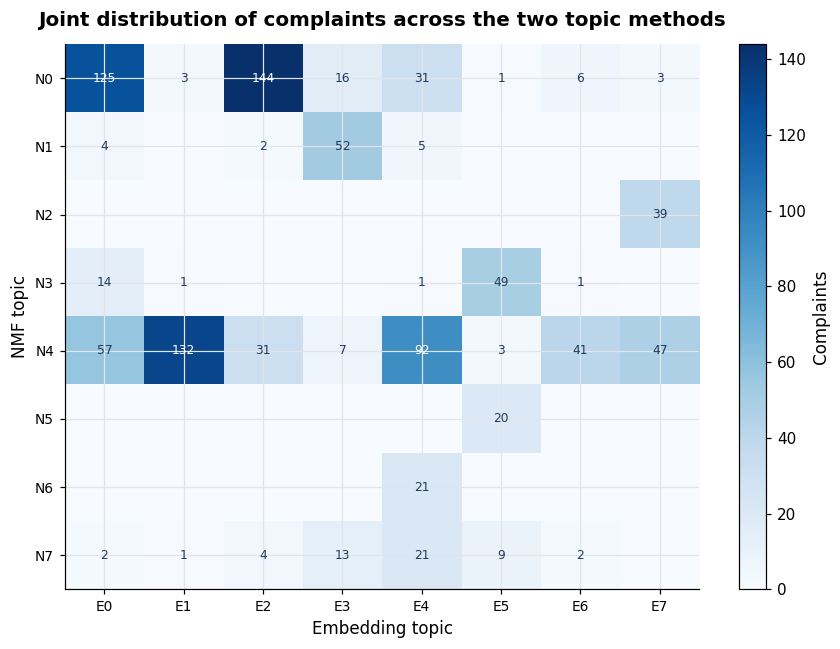

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
heat = ax.imshow(crosstab.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(crosstab.shape[1]))
ax.set_xticklabels([f"E{i}" for i in crosstab.columns], fontsize=9)
ax.set_yticks(range(crosstab.shape[0]))
ax.set_yticklabels([f"N{i}" for i in crosstab.index], fontsize=9)
ax.set_xlabel("Embedding topic")
ax.set_ylabel("NMF topic")
ax.set_title("Joint distribution of complaints across the two topic methods")
for (row, col), value in np.ndenumerate(crosstab.values):
    if value > 0:
        ax.text(col, row, str(int(value)), ha="center", va="center", fontsize=8, color="#1F3A5F" if value < crosstab.values.max()/2 else "white")
fig.colorbar(heat, ax=ax, label="Complaints")
fig.tight_layout()
save_figure(ctx, fig, "nmf_vs_embedding_crosstab")
plt.show()


In [8]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

n_in_both = int(text_mask.sum())
ari = adjusted_rand_score(nmf_assignments[text_mask], emb_assignments[text_mask])
nmi = normalized_mutual_info_score(nmf_assignments[text_mask], emb_assignments[text_mask])
agreement = pd.DataFrame({
    "metric": ["Adjusted Rand Index", "Normalized Mutual Information", "Complaints scored by both"],
    "value": [round(ari, 3), round(nmi, 3), n_in_both],
})
agreement


,metric,value
0,Adjusted Rand Index,0.21
1,Normalized Mutual Information,0.39
2,Complaints scored by both,"1,000.00"


In [9]:
def _risk_profile(method_name: str, assignments: pd.Series) -> pd.DataFrame:
    working = complaints.assign(topic_id=assignments)
    summary = (
        working[working["topic_id"] >= 0]
        .groupby("topic_id", as_index=False)
        .agg(
            complaints=("complaint_id", "size"),
            avg_risk=("risk_score", "mean"),
            high_risk_share_pct=("risk_level", lambda s: (s == "high").mean() * 100),
        )
        .assign(method=method_name)
    )
    summary["avg_risk"] = summary["avg_risk"].round(2)
    summary["high_risk_share_pct"] = summary["high_risk_share_pct"].round(1)
    return summary

nmf_profile = _risk_profile("nmf", nmf_assignments)
emb_profile = _risk_profile("embedding", emb_assignments)
side_by_side_risk = pd.concat([nmf_profile, emb_profile], ignore_index=True)
side_by_side_risk.sort_values(["method", "high_risk_share_pct"], ascending=[True, False]).reset_index(drop=True)


,topic_id,complaints,avg_risk,high_risk_share_pct,method
0,2,181,4.01,30.40,embedding
1,5,82,3.64,29.30,embedding
2,1,137,3.81,10.20,embedding
3,0,202,2.95,9.90,embedding
4,4,171,3.45,8.20,embedding
5,3,88,3.04,8.00,embedding
6,6,50,3.28,4.00,embedding
7,7,89,3.25,0.00,embedding
8,3,66,3.88,36.40,nmf
9,0,329,3.66,21.60,nmf


## 4. Insights

In [10]:
top_nmf = nmf_profile.sort_values("high_risk_share_pct", ascending=False).iloc[0]
top_emb = emb_profile.sort_values("high_risk_share_pct", ascending=False).iloc[0]

narrative = "\n".join([
    f"- **NMF** found its highest-risk topic at id {int(top_nmf['topic_id'])} "
    f"with {top_nmf['high_risk_share_pct']:.1f}% high-risk share across {int(top_nmf['complaints'])} complaints.",
    f"- **Embedding** found its highest-risk cluster at id {int(top_emb['topic_id'])} "
    f"with {top_emb['high_risk_share_pct']:.1f}% high-risk share across {int(top_emb['complaints'])} complaints.",
    f"- The two methods agree at ARI={ari:.2f} (1.0 = identical clustering, 0.0 = random). "
    "Modest overlap means each method captures axes the other misses.",
    "- Use NMF for the **default** pipeline (cheap, transparent, deterministic), and reach for "
    "embeddings when the NMF labels start to look generic or when narratives use heavy synonymy.",
])
display(Markdown(narrative))


- **NMF** found its highest-risk topic at id 3 with 36.4% high-risk share across 66 complaints.
- **Embedding** found its highest-risk cluster at id 2 with 30.4% high-risk share across 181 complaints.
- The two methods agree at ARI=0.21 (1.0 = identical clustering, 0.0 = random). Modest overlap means each method captures axes the other misses.
- Use NMF for the **default** pipeline (cheap, transparent, deterministic), and reach for embeddings when the NMF labels start to look generic or when narratives use heavy synonymy.

## Limitations

- Embedding cluster sizes are sensitive to the chosen `K`. KMeans assumes spherical clusters; HDBSCAN/BERTopic would handle outliers and non-spherical shapes better at the cost of more dependencies.
- The bundled sample is small (1,000 complaints, one month). Differences between the two methods will be more pronounced on multi-month, multi-product data.
- All comparison metrics use the heuristic `risk_level == "high"`, which is itself a triage signal rather than a validated outcome.
- Embedding cost matters: a CPU-only run of `all-MiniLM-L6-v2` over 1,000 narratives takes ~30 s; production batches at full CFPB scale (~3M records/year) will need batching, caching, or a smaller model.

## Exports

All tables and figures generated above are saved under `reports/notebook/11/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [11]:
save_table(ctx, labels_side_by_side, "topic_labels_side_by_side")
save_table(ctx, crosstab.reset_index(), "nmf_vs_embedding_crosstab")
save_table(ctx, agreement, "topic_method_agreement")
save_table(ctx, side_by_side_risk, "risk_profile_per_method")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())


[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/11/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/11/nmf_vs_embedding_crosstab.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/11/nmf_vs_embedding_crosstab.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/11/risk_profile_per_method.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/11/topic_labels_side_by_side.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/11/topic_method_agreement.csv')]